# Week 9: Gradient Boosting Algorithm

This week, I will be using a gradient boosting algorithm on my two datasets. I will first start by performing a randomized search for the best hyperparameters for each dataset and then will build the best model. I will then use these models to predict probabilities of the instance to have a target of 1 and build a decile table with lift. I am wondering if this model will perform better or the same as the random forest did in week 6.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import roc_curve, auc

In [6]:
model = xgb.XGBClassifier()

params = {'max_depth' : [2, 5, 10, 15], 'n_estimators' : [100, 200, 300,  400], 'learning_rate' : [0.1, 0.5, 1, 2], 'min_child_weight' : [1, 5, 10, 15], 'subsample' : [0.5, 0.7, 1], 'colsample_bytree' : [0.5, 0.7, 1], 'gamma' : [0, 1, 3, 5]}

random_search = RandomizedSearchCV(model, params, cv = 5, n_iter = 30)

## Dataset 1: Instacart Dataset

In [3]:
data1 = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/instacart.csv')

transform_cols = ['times_purchased', 'num_orders', 'frequency', 'Product Popularity', 'Last Product Order', 'Last Order', 'Orders Since Last Purchase']

for col in transform_cols:
    data1[f'log_{col}'] = np.log1p(data1[col])

data1_transformed = data1.drop(columns = ['times_purchased', 'num_orders', 'frequency', 'Product Popularity', 'Last Product Order', 'Last Order', 'Orders Since Last Purchase'])

data1_transformed.head()

,user_id,product_id,ordered,log_times_purchased,log_num_orders,log_frequency,log_Product Popularity,log_Last Product Order,log_Last Order,log_Orders Since Last Purchase
0,71,45,0.0,1.791759,3.178054,0.196710,0.005878,2.302585,3.178054,2.708050
1,71,117,1.0,2.995732,3.178054,0.602175,0.001219,3.178054,3.178054,0.000000
2,71,2078,0.0,0.693147,3.178054,0.042560,0.006478,1.386294,3.178054,3.044522
3,71,2825,0.0,1.098612,3.178054,0.083382,0.003743,1.945910,3.178054,2.890372
4,71,3376,1.0,1.098612,3.178054,0.083382,0.003602,2.995732,3.178054,1.609438


In [21]:
X = data1_transformed.drop(columns = ['ordered', 'user_id', 'product_id'])
y = data1_transformed['ordered']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [8]:
random_search.fit(X_train, y_train)
print(f'The best hyperparameters for dataset one are: {random_search.best_params_}')

The best hyperparameters for dataset one are: {'subsample': 0.7, 'n_estimators': 400, 'min_child_weight': 10, 'max_depth': 5, 'learning_rate': 0.1, 'gamma': 3, 'colsample_bytree': 1}


In [22]:
best_model = xgb.XGBClassifier(subsample = 0.7, n_estimators = 400, min_child_weight = 10, max_depth = 5, learning_rate = 0.1, gamma = 3, colsample_bytree = 1)

best_model.fit(X_train, y_train)

y_preds = best_model.predict_proba(X_test)[:, 1]

values = pd.DataFrame({'Predicted' : y_preds, 'Actual' : y_test})
values['decile'] = pd.qcut(values['Predicted'].rank(method = 'first'), q = 10, labels = False) + 1

lift_table = values.groupby('decile').agg(avg_predicted = ('Predicted', 'mean'), avg_liked = ('Actual', 'mean'))

overall_liked = y_test.mean()

lift_table['lift'] = lift_table['avg_liked']/overall_liked

lift_table['avg_predicted'] = lift_table['avg_predicted'].map(lambda x: f'{x:.3f}')
lift_table['avg_liked'] = lift_table['avg_liked'].map(lambda x: f'{x:.3f}')
lift_table['lift'] = lift_table['lift'].map(lambda x: f'{x:.3f}')

lift_table

,avg_predicted,avg_liked,lift
decile,,,
1,0.004,0.004,0.068
2,0.008,0.009,0.140
3,0.013,0.013,0.199
4,0.019,0.020,0.308
5,0.026,0.030,0.478
6,0.037,0.042,0.665
7,0.051,0.056,0.878
8,0.076,0.078,1.219
9,0.119,0.116,1.828


In [11]:
feature_names = X.columns

importances = best_model.feature_importances_

importance_df = pd.DataFrame({'Featuures' : feature_names, 'Importances' : importances}).sort_values(by = 'Importances', ascending = False)

importance_df

,Featuures,Importances
6,log_Orders Since Last Purchase,0.501078
2,log_frequency,0.231341
0,log_times_purchased,0.184069
3,log_Product Popularity,0.030966
4,log_Last Product Order,0.027730
1,log_num_orders,0.024816
5,log_Last Order,0.000000


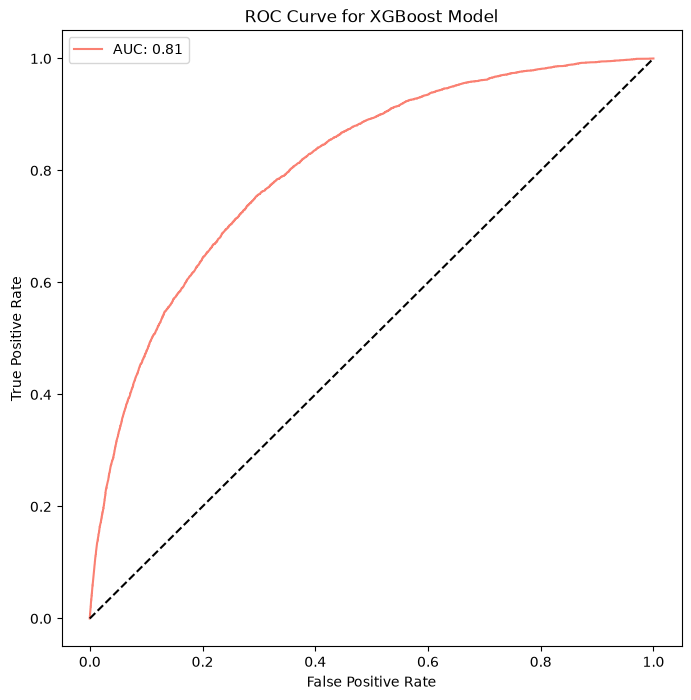

In [31]:
fpr, tpr, thresholds = roc_curve(y_test, y_preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 8))
plt.plot(fpr, tpr, color = 'salmon', label = f'AUC: {roc_auc:.2f}')
plt.plot([0,1], [0,1], color = 'black', ls = '--')
plt.title('ROC Curve for XGBoost Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()


## Dataset 2: Amazon Reviews Dataset

In [32]:
import ast
from sklearn.preprocessing import MultiLabelBinarizer

small_reviews = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/small_reviews%5B1%5D.csv')

small_meta = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/small_meta%5B1%5D.csv')

small_meta = small_meta.set_index(keys = 'parent_asin')

small_meta = small_meta.drop(columns = ['title', 'images'])

data2 = small_reviews.join(small_meta, on = 'parent_asin', how = 'inner')

data2 = data2.drop(columns = ['main_category', 'store', 'rating_number', 'videos', 'images', 'subtitle', 'author', 'bought_together', 'features', 'description', 'details', 'timestamp', 'text', 'title'])

data2['product_review_count'] = data2.groupby('asin').transform('size')
data2['user_review_count'] = data2.groupby('user_id').transform('size')

data2['price'] = data2['price'].fillna(data2['price'].median())

data2['categories'] = data2['categories'].apply(ast.literal_eval)

mlb = MultiLabelBinarizer()

categories = pd.DataFrame(mlb.fit_transform(data2['categories']), columns = mlb.classes_, index = data2.index)

top_30 = categories.sum().sort_values(ascending = False).head(31).index

categories = categories[top_30[1:31]]

data2 = data2.drop(columns = 'categories')

data2 = data2.join(categories)

columns_to_transform = ['helpful_vote', 'average_rating', 'price', 'product_review_count', 'user_review_count']

for col in columns_to_transform:
    data2[f'log_{col}'] = np.log1p(data2[col])

data2_transformed = data2.drop(columns = ['helpful_vote', 'average_rating', 'price', 'product_review_count', 'user_review_count'])

data2_transformed = data2_transformed.reset_index(drop = True)

for i in range(len(data2_transformed)):
    if data2_transformed.iloc[i]['rating'] == 4:
        data2_transformed.loc[i, 'liked'] = 1
    elif data2_transformed.iloc[i]['rating'] == 5:
        data2_transformed.loc[i, 'liked'] = 1
    else:
        data2_transformed.loc[i, 'liked'] = 0

X = data2_transformed.drop(columns = ['asin', 'parent_asin', 'user_id', 'liked', 'rating'])
y = data2_transformed['liked']

X.head()

,verified_purchase,Beverages,Snacks & Sweets,Pantry Staples,Coffee,Snack Foods,Candy & Chocolate,"Bottled Beverages, Water & Drink Mixes",Cooking & Baking,Breads & Bakery,Single-Serve Capsules & Pods,Tea,Cookies,Meat Snacks,"Soups, Stocks & Broths",Nuts & Seeds,Jerky,Juices,Ground Coffee,Breakfast Foods,Cereals,Granola,Fruit & Herbal Tea,Herbal,Bars,Roasted Coffee Beans,Whole Coffee Beans,"Canned, Jarred & Packaged Foods",Cold Cereals,"Baking Syrups, Sugars & Sweeteners",Black,log_helpful_vote,log_average_rating,log_price,log_product_review_count,log_user_review_count
0,False,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0.000000,1.704748,3.257712,0.693147,0.693147
1,True,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,3.295837,1.686399,3.351307,0.693147,0.693147
2,True,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0.000000,1.686399,2.889816,0.693147,1.098612
3,True,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000000,1.722767,2.771964,0.693147,1.098612
4,True,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000000,1.686399,3.395179,1.609438,0.693147


In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

random_search.fit(X_train, y_train)

print(f'The best hyperparameters for dataset 2 are: {random_search.best_params_}')

The best hyperparameters for dataset 2 are: {'subsample': 0.5, 'n_estimators': 300, 'min_child_weight': 10, 'max_depth': 2, 'learning_rate': 2, 'gamma': 0, 'colsample_bytree': 0.5}


In [34]:
best_model = xgb.XGBClassifier(subsample = 0.7, n_estimators = 200, min_child_weight = 1, max_depth = 2, learning_rate = 0.1, gamma = 1, colsample_bytree = 0.5)

best_model.fit(X_train, y_train)

y_preds = best_model.predict_proba(X_test)[:, 1]

values = pd.DataFrame({'Predicted' : y_preds, 'Actual' : y_test})
values['decile'] = pd.qcut(values['Predicted'].rank(method = 'first'), q = 10, labels = False) + 1

lift_table = values.groupby('decile').agg(avg_predicted = ('Predicted', 'mean'), avg_liked = ('Actual', 'mean'))

overall_liked = y_test.mean()

lift_table['lift'] = lift_table['avg_liked']/overall_liked

lift_table['avg_predicted'] = lift_table['avg_predicted'].map(lambda x: f'{x:.3f}')
lift_table['avg_liked'] = lift_table['avg_liked'].map(lambda x: f'{x:.3f}')
lift_table['lift'] = lift_table['lift'].map(lambda x: f'{x:.3f}')

lift_table

,avg_predicted,avg_liked,lift
decile,,,
1,0.582,0.533,0.638
2,0.777,0.867,1.037
3,0.845,0.786,0.940
4,0.884,0.933,1.117
5,0.908,0.857,1.026
6,0.929,0.800,0.957
7,0.943,0.929,1.111
8,0.952,0.800,0.957
9,0.963,0.857,1.026


In [16]:
feature_names = X.columns

importances = best_model.feature_importances_

importance_df = pd.DataFrame({'Featuures' : feature_names, 'Importances' : importances}).sort_values(by = 'Importances', ascending = False)

importance_df

,Featuures,Importances
32,log_average_rating,0.074061
12,Cookies,0.069300
2,Snacks & Sweets,0.060693
4,Coffee,0.060652
33,log_price,0.056335
35,log_user_review_count,0.053966
31,log_helpful_vote,0.051930
8,Cooking & Baking,0.049271
6,Candy & Chocolate,0.045609
7,"Bottled Beverages, Water & Drink Mixes",0.045025


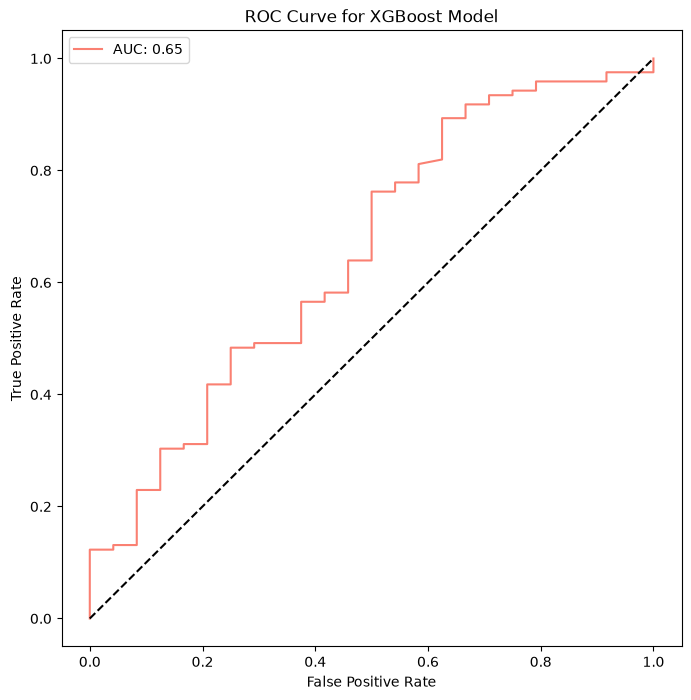

In [35]:
fpr, tpr, thresholds = roc_curve(y_test, y_preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 8))
plt.plot(fpr, tpr, color = 'salmon', label = f'AUC: {roc_auc:.2f}')
plt.plot([0,1], [0,1], color = 'black', ls = '--')
plt.title('ROC Curve for XGBoost Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

## Conclusion

Looking at the results, for both datasets, the XGBoost model was the top performing model compared to other hyperparameter tuned models. For the first dataset, I found that the lift for the top decile was the highest compared to the other algorithms I have tested so far. For the second dataset, the top decile lift was the same as the best performing model which is logistic regression. This is surprising as I assumed the reason random forest did not perform as well due to the added complexity, but this was proven wrong as XGBoost is a more complex model compared to random forest and it did just as well as logistic regression. I also found the feature importances interesting as they differed from the random forest importances. What was especially interesting is the second and third most important features for the second dataset were binary features, which makes me wonder if items in those categories have higher reviews generally so that means if the item is in that category it is more likely to be liked.

For this week, I also constructed the ROC curves with their respective AUC values as well to have another metric to measure model performance as the lift is not as reliable for the second dataset due to the high positive rate already. Looking at dataset one, it has an AUC of 0.81 which shows the model is doing a good job at identifying which customers are more likely to reorder a product. However, for the second dataset, we can see the AUC is 0.65 which is showing the model is performing slightly better than random guessing, but it isn't doing very well. This could be caused by not having enough informative features as the majority of features are binary classifiers for the item.